# Models

Holt-Winters (ETS), SARIMA and gradient boosting, all on the log of daily requests and run through the same backtest as the baselines.

In [1]:
import sys

sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from src.data import model_series
from src.backtest import backtest, score
from src.models import (naive, seasonal_naive, moving_average, ets, sarima, gradient_boosting,
                        big_holiday, future_dates)

FIGURES = "../reports/figures/"

In [2]:
y, usable = model_series(pd.read_parquet("../data/daily.parquet"))

models = {
    "naive": naive,
    "seasonal naive": seasonal_naive,
    "7-day average": moving_average,
    "ETS": ets,
    "SARIMA": sarima,
    "gradient boosting": gradient_boosting,
}
results = {name: backtest(model, y, usable) for name, model in models.items()}
table = pd.DataFrame({name: score(r) for name, r in results.items()}).T
table.round(3)

,MAPE,MASE,MAE,origins
naive,39.833,1.768,961.471,51.0
seasonal naive,24.745,1.149,615.489,51.0
7-day average,33.020,1.228,667.962,51.0
ETS,25.626,1.167,627.626,51.0
SARIMA,20.799,0.962,518.781,51.0
gradient boosting,20.388,0.985,527.961,51.0


SARIMA and gradient boosting both beat seasonal naive by about 4 points of MAPE and get a MASE below 1. ETS is slightly worse than seasonal naive.

## Variants

In [3]:
def ets_no_trend(history, horizon):
    fit = ExponentialSmoothing(np.log(history), trend=None, seasonal="add", seasonal_periods=7).fit()
    return np.exp(fit.forecast(horizon).to_numpy())


def sarima_no_holidays(history, horizon):
    fit = SARIMAX(np.log(history), order=(1, 0, 1), seasonal_order=(0, 1, 1, 7)).fit(disp=False)
    return np.exp(fit.forecast(horizon).to_numpy())


def boosting_leaf_20(history, horizon):
    return gradient_boosting(history, horizon, min_samples_leaf=20)


variants = {"ETS without trend": ets_no_trend, "SARIMA without holidays": sarima_no_holidays,
            "gradient boosting, leaf 20": boosting_leaf_20}
variant_results = {name: backtest(model, y, usable) for name, model in variants.items()}
pd.DataFrame({name: score(r) for name, r in variant_results.items()}).T.round(3)

,MAPE,MASE,MAE,origins
ETS without trend,25.830,1.177,632.780,51.0
SARIMA without holidays,22.112,1.005,541.272,51.0
"gradient boosting, leaf 20",21.113,1.013,542.364,51.0


In [4]:
def ape(r):
    ok = r[r["usable"]]
    return (ok["actual"] - ok["forecast"]).abs() / ok["actual"] * 100


def breakdown(r):
    ok = r[r["usable"]]
    winter = ok["date"].dt.month.isin([11, 12, 1, 2, 3])
    holiday = big_holiday(pd.DatetimeIndex(ok["date"])).astype(bool)
    e = ape(r)
    return pd.Series({"Nov to Mar": e[winter].mean(), "Apr to Oct": e[~winter].mean(), "big holidays": e[holiday].mean()})


all_results = {**results, **variant_results}
pd.DataFrame({name: breakdown(r) for name, r in all_results.items()}).T.round(1)

,Nov to Mar,Apr to Oct,big holidays
naive,39.4,40.2,29.0
seasonal naive,36.2,16.4,88.9
7-day average,34.3,32.1,80.8
ETS,35.3,18.6,88.0
SARIMA,27.5,15.9,26.7
gradient boosting,26.7,15.8,36.5
ETS without trend,35.7,18.6,88.1
SARIMA without holidays,28.4,17.5,74.6
"gradient boosting, leaf 20",27.2,16.6,100.0


The holiday regressor is worth 1.3 points of MAPE to SARIMA (22.1% without it). Gradient boosting with sklearn's default leaf size of 20 never splits on the holiday flag, since the history only has 5 to 12 big holidays, so it forecasts them like normal days and is 100% off on them. With a leaf size of 5 it learns them. Taking the trend out of ETS doesn't help either.

## Choice

SARIMA. Gradient boosting has a slightly lower MAPE (20.4% against 20.8%), but SARIMA is better on MASE and MAE, which weigh the busy winter days more, and those are the days that decide how many agents are needed. SARIMA also gives prediction intervals directly, which the final forecast needs.

## Residuals

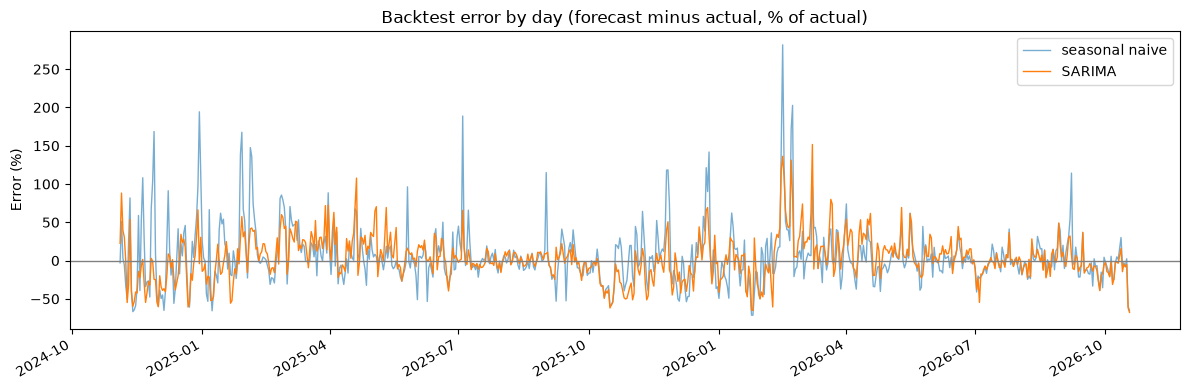

In [5]:
def pct_error(r):
    ok = r[r["usable"]]
    return pd.Series(((ok["forecast"] - ok["actual"]) / ok["actual"] * 100).to_numpy(), index=ok["date"])


fig, ax = plt.subplots(figsize=(12, 4))
pct_error(results["seasonal naive"]).plot(ax=ax, linewidth=1, alpha=0.6, label="seasonal naive")
pct_error(results["SARIMA"]).plot(ax=ax, linewidth=1, label="SARIMA")
ax.axhline(0, color="grey", linewidth=1)
ax.set_title("Backtest error by day (forecast minus actual, % of actual)")
ax.set_xlabel("")
ax.set_ylabel("Error (%)")
ax.legend()
fig.tight_layout()
fig.savefig(FIGURES + "backtest_errors.png", dpi=150)
plt.show()

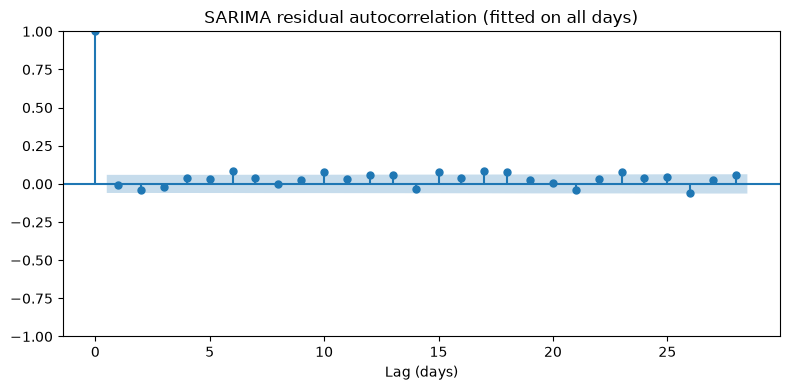

In [6]:
fit = SARIMAX(np.log(y), exog=big_holiday(y.index).reshape(-1, 1), order=(1, 0, 1), seasonal_order=(0, 1, 1, 7)).fit(disp=False)
resid = fit.resid[8:]

fig, ax = plt.subplots(figsize=(8, 4))
plot_acf(resid, lags=28, ax=ax)
ax.set_title("SARIMA residual autocorrelation (fitted on all days)")
ax.set_xlabel("Lag (days)")
fig.tight_layout()
fig.savefig(FIGURES + "sarima_residual_acf.png", dpi=150)
plt.show()

In [7]:
fit.summary().tables[1]

,coef,std err,z,P>|z|,[0.025,0.975]
x1,-0.5580,0.029,-19.146,0.000,-0.615,-0.501
ar.L1,0.6528,0.031,21.022,0.000,0.592,0.714
ma.L1,0.0995,0.036,2.800,0.005,0.030,0.169
ma.S.L7,-0.7071,0.019,-36.696,0.000,-0.745,-0.669
sigma2,0.0374,0.001,35.720,0.000,0.035,0.039


The biggest misses for both models are winter: SARIMA undershoots the start of a cold snap and overshoots the week after it ends, just less than seasonal naive does. Outside winter the errors mostly stay within about 20%. The residual autocorrelation is small at most lags, so there isn't much weekly structure left that the model is missing.